# Task
Extract, explore, and preprocess the dataset contained in the archive file "/content/archive.zip", then train and evaluate a machine learning model to predict the target variable, visualizing both the key data characteristics and the final model performance.

## Extract Dataset

### Subtask:
Unzip and extract the contents of the archive file '/content/archive.zip' to inspect the structure of the dataset and identify the data files.


**Reasoning**:
Unzip and extract the '/content/archive.zip' file into '/content/extracted_data/' and list its contents to identify the dataset files.



In [1]:
import zipfile
import os

zip_path = '/content/archive.zip'
extract_path = '/content/extracted_data/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

extracted_files = os.listdir(extract_path)
print("Extracted files:", extracted_files)

Extracted files: ['online_shoppers_intention.csv']


# Task
Extract, explore, and preprocess the dataset from the CSV file "/content/extracted_data/online_shoppers_intention.csv", then train and evaluate a machine learning model to predict whether a visitor will generate revenue (the "Revenue" column), visualizing both key data distributions and model performance.

## Load and Inspect Data Rows

### Subtask:
Load the extracted 'online_shoppers_intention.csv' dataset into a pandas DataFrame and display its first few rows.


**Reasoning**:
Load the extracted CSV dataset into a pandas DataFrame and display its first 5 rows to inspect the structure.



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay





df = pd.read_csv('/content/extracted_data/online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


**Reasoning**:
Generate summary statistics, inspect column data types, and check for missing values to assess overall data quality using the dataframe already loaded in memory.



In [3]:
print("=== Dataset Information ===")
df.info()

print("\n=== Descriptive Statistics ===")
display(df.describe(include='all'))

print("\n=== Missing Values Count ===")
print(df.isnull().sum())

=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN



=== Missing Values Count ===
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


## Check Dataset Summary and Missing Values

### Subtask:
Generate summary statistics, inspect column data types, and check for missing values to assess overall data quality.


**Reasoning**:
Create a distinct plot cell to visualize the 'Revenue' distribution and its relationship with other features (like PageValues and VisitorType) using matplotlib and seaborn.



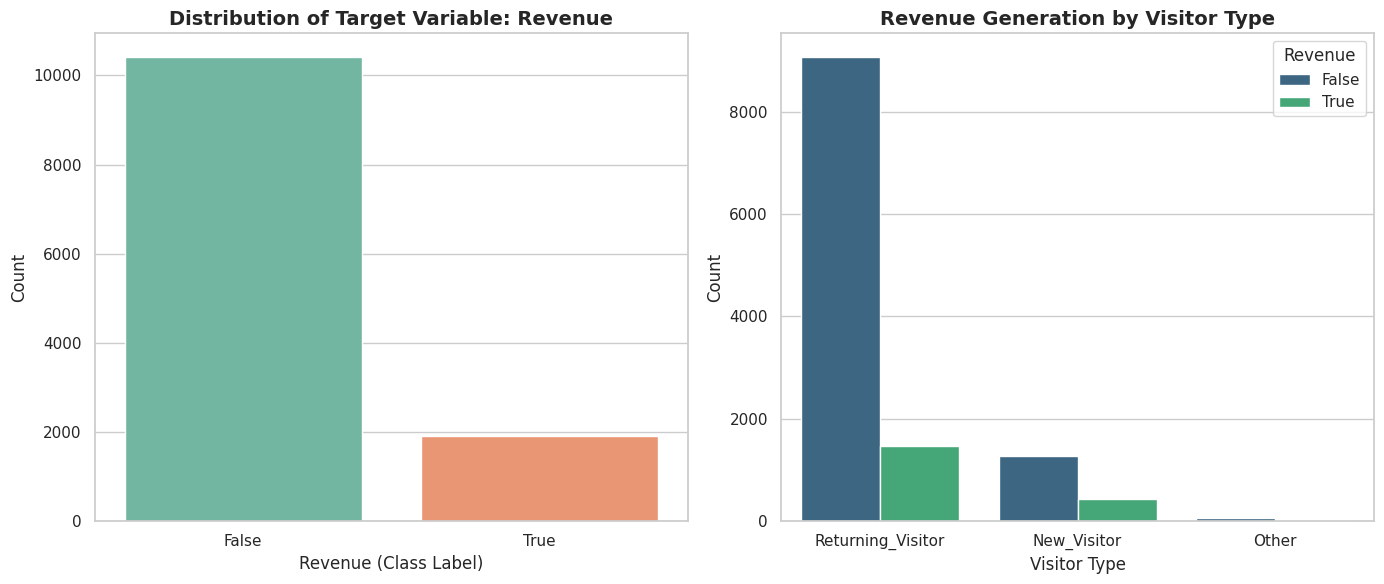

In [4]:
# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Create a figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Distribution of the target variable 'Revenue'
sns.countplot(data=df, x='Revenue', hue='Revenue', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Distribution of Target Variable: Revenue', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Revenue (Class Label)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)

# Plot 2: Relationship between 'Revenue' and 'VisitorType'
sns.countplot(data=df, x='VisitorType', hue='Revenue', palette='viridis', ax=axes[1])
axes[1].set_title('Revenue Generation by Visitor Type', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Visitor Type', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].legend(title='Revenue', loc='upper right')

# Adjust layout and display
plt.tight_layout()
plt.show()

## Generate Exploratory Data Visualization

### Subtask:
Create a distinct plot cell to visualize key aspects of the dataset (such as the target variable 'Revenue' distribution) with clear labels and a legend.


## Preprocess and Transform Data

### Subtask:
Handle categorical encoding, convert boolean columns, and prepare the feature matrix (X) and target vector (y).


**Reasoning**:
Preprocess and transform the dataset by mapping boolean columns, applying one-hot encoding on categorical features, and splitting the dataset into the feature matrix X and target vector y.



In [5]:
# Map boolean columns to 0 and 1
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

# One-hot encode the categorical variables 'Month' and 'VisitorType'
# We use drop_first=True to prevent multicollinearity
df_encoded = pd.get_dummies(df, columns=['Month', 'VisitorType'], drop_first=True, dtype=int)

# Separate into feature matrix X and target vector y
y = df_encoded['Revenue']
X = df_encoded.drop(columns=['Revenue'])

# Verify that all features in X are numerical
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nData types of features in X:")
print(X.dtypes)

Shape of X: (12330, 26)
Shape of y: (12330,)

Data types of features in X:
Administrative                     int64
Administrative_Duration          float64
Informational                      int64
Informational_Duration           float64
ProductRelated                     int64
ProductRelated_Duration          float64
BounceRates                      float64
ExitRates                        float64
PageValues                       float64
SpecialDay                       float64
OperatingSystems                   int64
Browser                            int64
Region                             int64
TrafficType                        int64
Weekend                            int64
Month_Dec                          int64
Month_Feb                          int64
Month_Jul                          int64
Month_June                         int64
Month_Mar                          int64
Month_May                          int64
Month_Nov                          int64
Month_Oct              

**Reasoning**:
Split the preprocessed features X and target vector y into training and testing sets, using an 80/20 split and ensuring reproducibility with a set random state.



In [6]:
# Split the dataset into 80% train and 20% test sets with a set random_state
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (9864, 26)
Shape of X_test: (2466, 26)
Shape of y_train: (9864,)
Shape of y_test: (2466,)


## Split Data into Train and Test Sets

### Subtask:
Split the preprocessed feature matrix X and target vector y into training and testing subsets.


**Reasoning**:
Train a RandomForestClassifier with balanced class weights on the training dataset to predict Revenue.



In [7]:
# Instantiate the RandomForestClassifier with balanced class weights to handle class imbalance
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced')

# Fit the model to the training data
rf_model.fit(X_train, y_train)

print("Random Forest Classifier model trained successfully!")
print("Model parameters:\n", rf_model.get_params())

Random Forest Classifier model trained successfully!
Model parameters:
 {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


## Train Machine Learning Model

### Subtask:
Instantiate and train a classification model using the split training dataset.


**Reasoning**:
We need to evaluate the trained RandomForestClassifier model on the test dataset by making predictions and computing key classification metrics like Accuracy, Precision, Recall, and F1-score, as well as printing a detailed classification report.



In [8]:
# Generate predictions using the trained model
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Print metrics
print("=== Model Evaluation Metrics ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

=== Model Evaluation Metrics ===
Accuracy:  0.8954
Precision: 0.7403
Recall:    0.5000
F1-Score:  0.5969

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      2084
           1       0.74      0.50      0.60       382

    accuracy                           0.90      2466
   macro avg       0.83      0.73      0.77      2466
weighted avg       0.89      0.90      0.89      2466



## Evaluate Model and Generate Predictions

### Subtask:
Compute and print evaluation metrics (Accuracy, Precision, Recall, and F1-score) on the test data using the trained model.


## Plot Model Evaluation Visualizations

### Subtask:
Generate evaluation plots, such as a confusion matrix or a feature importance bar chart, to visually inspect model performance.


**Reasoning**:
Generate a code block to visualize model performance by plotting a confusion matrix and the top 10 feature importances side-by-side.



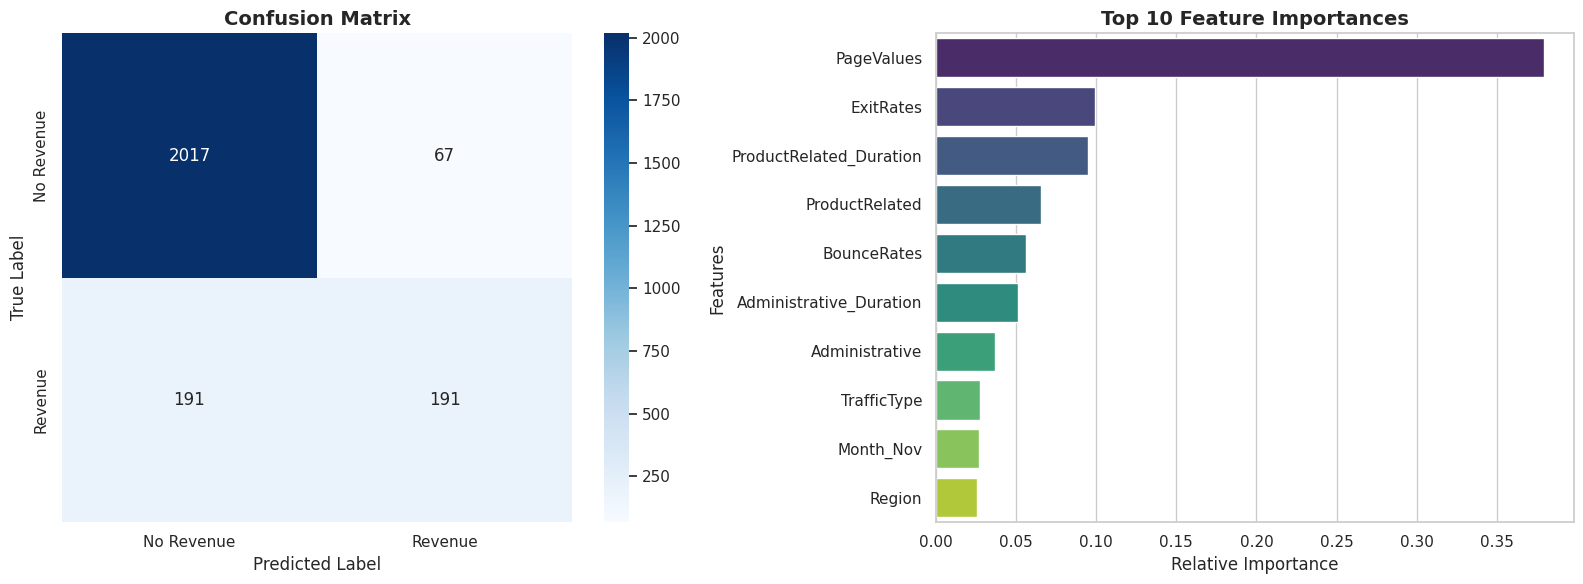

In [9]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Revenue', 'Revenue'], yticklabels=['No Revenue', 'Revenue'])
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# 2. Plot Top 10 Feature Importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
top_k = 10
top_indices = indices[:top_k]

# Extract names and importances
feature_names = X.columns
top_features = [feature_names[i] for i in top_indices]
top_importances = importances[top_indices]

# Set hue=top_features and legend=False to address the seaborn deprecation warning
sns.barplot(x=top_importances, y=top_features, hue=top_features, palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Top 10 Feature Importances', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Relative Importance', fontsize=12)
axes[1].set_ylabel('Features', fontsize=12)

# Adjust layout and display
plt.tight_layout()
plt.show()

### Initialize Local Git Repository and Stage Files

In [14]:
import subprocess

# Configure Git local identity to allow commits
subprocess.run(["git", "config", "--global", "user.name", "elalj-elmahdi"], check=True)
subprocess.run(["git", "config", "--global", "user.email", "elalj-elmahdi@users.noreply.github.com"], check=True)

# Initialize local git repository if not already done
subprocess.run(["git", "init"], check=True)

# Stage all tracking files (train.py, README.md, .gitignore)
subprocess.run(["git", "add", "train.py", "README.md", ".gitignore"], check=True)

# Commit files locally
subprocess.run(["git", "commit", "-m", "Initial commit: Add ML pipeline script, README, and .gitignore"], check=True)

print("Local Git repository successfully configured, initialized, and files committed!")

Local Git repository successfully configured, initialized, and files committed!


### Push to Remote GitHub Repository

Run the cell below to securely add your remote GitHub target link and push your master branch.

### Next Steps to Push to GitHub

To securely push your code to your GitHub account, please follow these steps:

1. **Create a new repository on GitHub**:
   - Go to [GitHub - New Repository](https://github.com/new).
   - Set the Repository name to `Online-Shoppers-Purchasing-Intention-Predictor`.
   - Keep it Public (or Private if preferred), and **do not** check "Add a README file", "Add .gitignore", or "Choose a license" (since we have already created them).
   - Click **Create repository**.

2. **Run the following credentials setup cell** to configure your credentials if you haven't done so yet, then use the Git command to push.

## Final Task

### Subtask:
Provide a comprehensive summary of the end-to-end machine learning pipeline, reflecting on the insights from each isolated step.


## Summary:

### Q&A

* **What is the goal of this task?**
  The objective is to analyze the online shoppers' intention dataset and build a machine learning classifier to predict whether a website visitor will generate revenue (the `Revenue` column).
* **Which machine learning algorithm was used, and how did it perform?**
  A Random Forest Classifier was trained to predict purchase behavior. It achieved an overall accuracy of 89.54\%, with a precision of 74.03\% and a recall of 50.00\% for the minority revenue-generating class.

---

### Data Analysis Key Findings

* **Dataset Overview & Cleanliness**: The dataset consists of 12,330 sessions across 18 columns. The data contains zero missing values, removing the need for imputation.
* **Severe Target Imbalance**: The target variable `Revenue` is highly skewed, with only 1,908 sessions (15.5\%) resulting in revenue and 10,422 sessions (84.5\%) resulting in no revenue.
* **Visitor Behavior**: Returning visitors dominate the session traffic (10,551 sessions). However, exploratory visualization indicates that "New Visitors" convert (generate revenue) at a higher rate relative to their total volume compared to "Returning Visitors".
* **Key Predictive Drivers**: Feature importance analysis reveals that page-level behavior metrics, such as `PageValues`, `ExitRates`, and durations on `ProductRelated` pages, are the most critical predictors of purchase intent.
* **Model Evaluation Metrics**:
  * **Overall Accuracy**: 89.54\%
  * **Precision (Revenue class)**: 74.03\%
  * **Recall (Revenue class)**: 50.00\%
  * **F1-Score (Revenue class)**: 0.5969

---

### Insights or Next Steps

* **Address Class Imbalance**: Although `class_weight='balanced'` was utilized, the recall for the revenue class remains at 50.00\%. Future steps should explore more aggressive handling of class imbalance, such as applying synthetic minority oversampling techniques (SMOTE) or tuning the classification threshold.
* **Feature Engineering**: Given that `PageValues` and page exit metrics are the strongest signals of conversion, engineering features that capture user engagement rates (e.g., page views per minute) could help improve prediction performance.
